# Whole Sun Cost Estimate

In [5]:
%pylab inline

Populating the interactive namespace from numpy and matplotlib


In [39]:
from numpy import pi,where,linspace,maximum
from astropy import units as u
from astropy import constants as c
from matplotlib.pyplot import plot,semilogx,semilogy,xlabel,ylabel

In [7]:
A_sun=4*pi*c.R_sun**2
A_sun

<Quantity 6.0821044e+18 m2>

With the Volleyball geometry layout we can cover the whole Sun with Cartesian patches, using typically 16 to 32 cubed cells per partch.  The cost of a cell update is approximately 1 core-microseconds on a CPU (GPU acceleration developments are also ongoing). 

Updates in DISPATCH are done based on the local Courant condition -- not on the global one.  Assuming for simplicity that layers of patches are thin relative to scale heights, we can thus base estimate of cost on the local sound speed, cell layer by cell layer, using for example Model S:

In [8]:
top='c:/cygwin64/home/codes/dispatch2/'
import sys
sys.path.insert(0,top+'utilities/python')

In [9]:
from dispatch.EOS import interp,integral,deriv
from dispatch.solar_models import JCD_S

In-lined copies of the procedures imported above:

In [29]:
import scipy
def interp(x,y,x0):
    """ Interpolate in x[:] and y[:] to x-coordinat(s) x0
    """
    kind='cubic'
    f=scipy.interpolate.interp1d(x,y,kind,fill_value='extrapolate')
    return f(x0)

def integral(x,y,y1=None):
    """ Integrate over x[:],y[:] with optional derivate y1[:] 
    """
    if y1 is None:
        y1=deriv(x,y)
    f=np.zeros(len(x))
    for i in range(1,len(x)):
        dx=x[i]-x[i-1]
        f[i]=f[i-1]+dx*(y[i]+y[i-1])/2+dx**2*(y1[i-1]-y1[i])/12
    return f

Model S reader:

In [11]:
import os
import numpy as np

class JCD_S(object):
    def __init__(self,file='JCD_model_S.txt',top='~/codes/dispatch2',verbose=0):
        os.chdir(top+'/data/solar_models')
        with open(file,'r') as fd:
            a=[]
            for line in fd:
                line=line.rstrip()
                if line.startswith('#'):
                    if verbose>1:
                        print(line)
                else:
                    a.append([float(word) for word in line.split()])
        a=np.array(a).T
        self.r     =a[0]
        self.cs    =a[1]
        self.rho   =a[2]
        self.P     =a[3]
        self.gamma1=a[4]
        self.T     =a[5]
        if verbose>0:
            print(vars(self).keys())

Read model, showing attributes:

In [12]:
model=JCD_S(top=top,verbose=1)

dict_keys(['r', 'cs', 'rho', 'P', 'gamma1', 'T'])


Sound speed (CGS units)

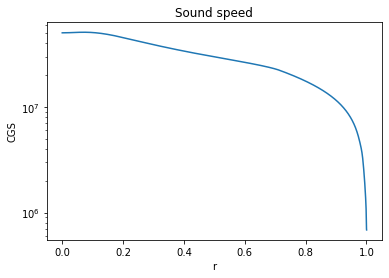

In [13]:
semilogy(model.r,model.cs)
xlabel('r'); ylabel('CGS'); title('Sound speed');

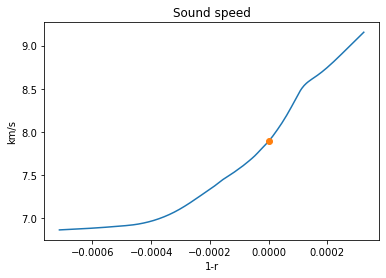

In [14]:
w=where(model.T < 1e4)
plot(1-model.r[w],model.cs[w]/1e5)
w0=where(model.r==1)[0]
plot(1-model.r[w0],model.cs[w0]/1e5,'o');
xlabel('1-r'); ylabel('km/s'); title('Sound speed');

Near-surface temperature stratification:

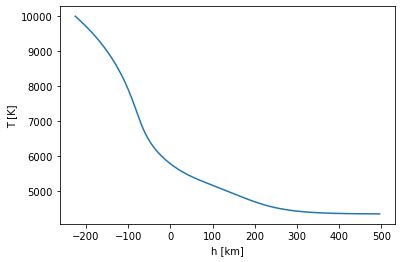

In [15]:
w=where(model.T < 1e4)
plot((model.r[w]-1)*c.R_sun.to('km'),model.T[w])
ylabel('T [K]'); xlabel('h [km]');

Radius and density in CGS unit values:

In [16]:
r=model.r[::-1]*c.R_sun.cgs.value                        # radius in cm values
rho=model.rho[::-1]                                      # density in CGS values

Integrate and check that the mass is OK:

In [17]:
M=(4*pi*integral(r,rho*r**2)*u.g)[1:].decompose()        # M(r) in MKS (excluding R=0)
M[-1]/c.M_sun

<Quantity 0.99905308>

Compute acceleration of gravity, skipping the central point

In [18]:
R=model.r[::-1][1:]*c.R_sun
g=c.G*M/R**2
g[-1]

<Quantity 273.55046209 m / s2>

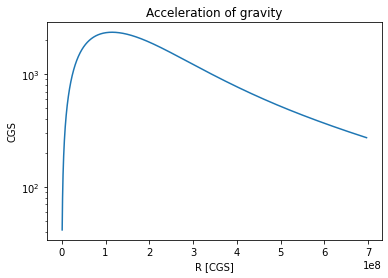

In [19]:
semilogy(R,g);
xlabel('R [CGS]'); ylabel('CGS'); title('Acceleration of gravity');

The pressure scale height is $H=P/g\rho$:

In [20]:
rho=(model.rho[::-1]*u.g/u.cm**3)[1:].decompose()
P=(model.P[::-1]*u.g/(u.cm*u.s**2))[1:].decompose()
H=P/(g*rho)
H[-1].to('km')

<Quantity 104.98701777 km>

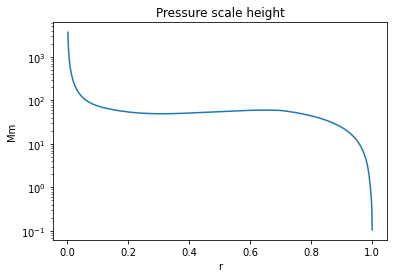

In [21]:
r=R/c.R_sun
semilogy(r,H/1e6);
xlabel('r'); ylabel('Mm'); title('Pressure scale height');

In [32]:
interp(r,h,0.5)

array(0.07905179)

In [62]:
h=H/c.R_sun   # scale height in radius units
nz=32         # number of cells per layer
C=0.16        # fraction of scale height
r1=r[-1]      # non-dimensional radius
n=0
while r1>0:
    h1=interp(r,h,r1)
    n1=4*pi*r1**2/(C*h1)**2*nz
    n+=n1
    r1=r1-h1*C*nz
print(n/1e10)

108.7424753591861


In [64]:
nv=8
nt=5
n*nt*nv*4e-12

<Quantity 173.98796057>

## Cost analysis

We use cells that are a fraction ds of the scale height, with for example ds=0.25 known to give quantitatively OK results at the surface (this is about 25 km -- Hotta used 48 km vertically and 192 km horizontally).  

The number of cells for a given radius is then

In [36]:
ds=0.25
dR=ds*H
N=4*pi*(R/dR)**2

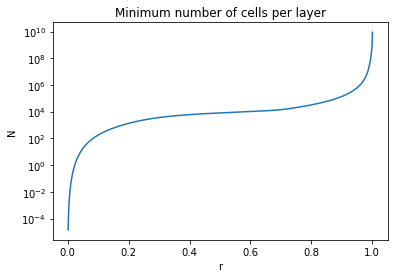

In [37]:
semilogy(r,N);
xlabel('r'); ylabel('N'); title('Minimum number of cells per layer');

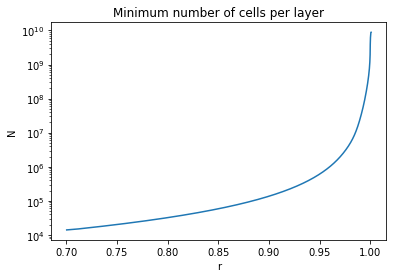

In [38]:
w=where((R/c.R_sun)>0.7)
semilogy(R[w]/c.R_sun,N[w]);
xlabel('r'); ylabel('N');title('Minimum number of cells per layer');

Evidently, the cost is very much concentrated to the surface layers

The number of surface cells, for example, is

In [39]:
N[-1]

<Quantity 8.84140715e+09>

The update cost for one surface layer is the cost per cell times this, so it takes about 2.5 core-hours to update one surface layer.

In [40]:
cost=N*1e-6*u.s
cost[-1].to('h')

<Quantity 2.45594643 h>

To get the update cost per unit solar time we need to multiply with the sound speed and divide with the cell size times the Courant number C:

In [41]:
cs=(model.cs[::-1][1:]*u.cm/u.s).decompose()
cs[-1]

<Quantity 6864.388 m / s>

In [42]:
C=0.3
cost_per_unit_time=cost*cs/dR/C

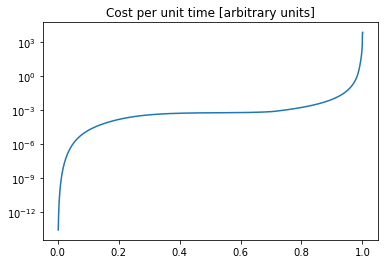

In [43]:
semilogy(r,cost_per_unit_time);
title('Cost per unit time [arbitrary units]');

In [44]:
print("The cost per unit time at the surface is about {:.0f} core-hours per second".format(
    cost_per_unit_time[-1]/3600))

The cost per unit time at the surface is about 2 core-hours per second


To get the cost per unit time and radius we need to divide with dR:

In [45]:
cost_per_unit_time_and_radius=cost_per_unit_time/dR

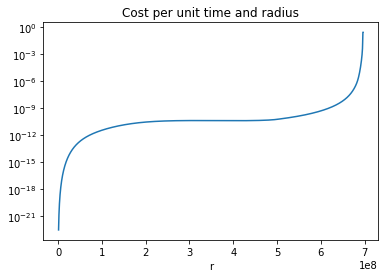

In [46]:
semilogy(R,cost_per_unit_time_and_radius);
xlabel('r'); ylabel(''); title('Cost per unit time and radius');

and to get the accumulated cost we need to integrate this over radius:

In [47]:
accumulated_cost=integral(R.value,cost_per_unit_time_and_radius.value)

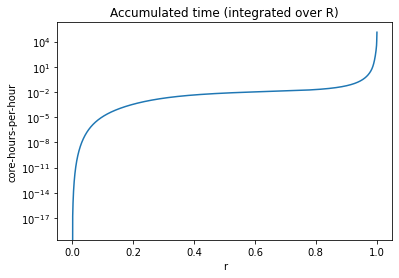

In [48]:
semilogy(r,accumulated_cost);
xlabel('r'); ylabel('core-hours-per-hour'); title('Accumulated time (integrated over R)');

In [49]:
print("The accumulated cost per unit time is about {:.0f} core-hours per second".format(
    accumulated_cost[-1]/3600.))

The accumulated cost per unit time is about 36 core-hours per second


In [50]:
h=(R-c.R_sun).to('km').value
w=where(h > -500)

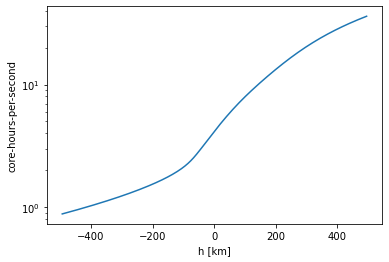

In [51]:
xlabel('h [km]'); ylabel('core-hours-per-second'); semilogy((R[w]-c.R_sun).to('km'),accumulated_cost[w]/3600);

### Cost percentiles

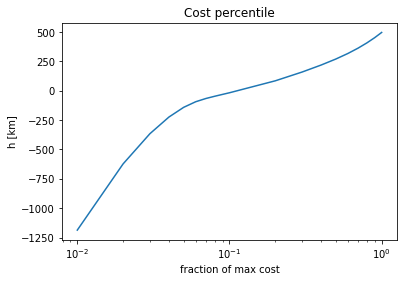

In [52]:
import scipy
max_cost=accumulated_cost[-1]
pp=[]
hh=[]
for p in linspace(0.01,0.09,9):
    pp.append(p)
    h=(interp(accumulated_cost,R.value,max_cost*p)-c.R_sun.value)/1e3
    hh.append(h)
for p in linspace(0.1,0.9,9):
    pp.append(p)
    h=(interp(accumulated_cost,R.value,max_cost*p)-c.R_sun.value)/1e3
    hh.append(h)
pp.append(1)
hh.append((R.max()-c.R_sun).value/1e3)
semilogx(pp,hh)
xlabel('fraction of max cost'); ylabel('h [km]');
title('Cost percentile');

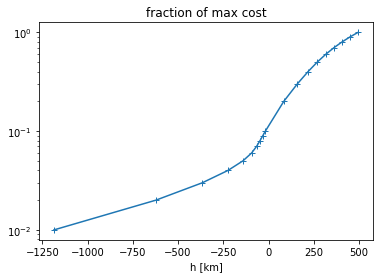

In [53]:
semilogy(hh,pp,'-+')
title('fraction of max cost'); xlabel('h [km]');

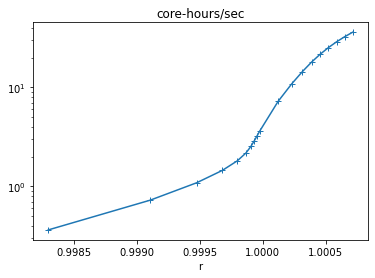

In [54]:
semilogy(1+hh/(1e-3*c.R_sun.value),[p*max_cost/3600 for p in pp],'-+')
title('core-hours/sec'); xlabel('r');

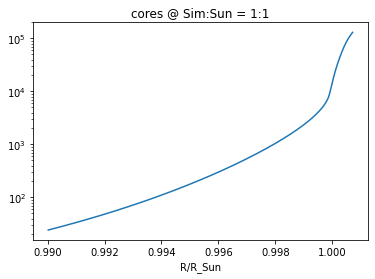

In [55]:
w=where(R/c.R_sun > 0.99)
semilogy(R[w]/c.R_sun,accumulated_cost[w])
title('cores @ Sim:Sun = 1:1'); xlabel('R/R_Sun');

In conclusion, if we -- as many others have done (eg. Hotta et al 2016, Science) -- cool the surface with a thin cooling layer, we can reduce the cost dramatically. As shown by Hotta et al (2019, Science Advances) using a thin cooling layer has very little effect on the dynamics of the deep CZ, and as done by Hotta et al one can run shorter runs with complete radius coverage.

At 1% of the max cost (cooling layer = 0.002 = 1.4 Mm), for example, the accumulated cost is only 20 core minutes per second solar time, and on on 1300 cores (less than 30 nodes), we could do one-to-one:  __One solar day in one day on 30 nodes x 48 cores with H/4 resolution__.

### Discrete cell sizes

In [57]:
i0=-1
P[i0].value

94.557639

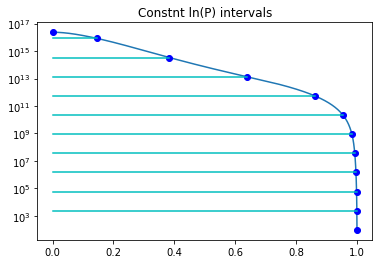

In [58]:
ng=16; ds=0.2; f=np.exp(ng*ds)
semilogy(r,P);
i0=len(r)-1; plot(r[i0],P[i0],'ob');
while (i0>0):
    i=i0; P0=P[i0]
    P1=P0*f
    while(P[i]<P1 and i>0):
        i=i-1
    i0=i
    plot(r[i0],P[i0],'ob')
    x=[0,r[i0]]
    P0=P[i0].value
    y=[P0,P0]
    plot(x,y,'-c')
title('Constnt ln(P) intervals');

In [ ]:
print(f**0.5-1,f**(-0.5)-1)

### Convection Zone dynamical time

What is the typical dynamical time for downflowing gas?   A rough estimate may be obtained by assuming that the convective flux is of the order of or larger than the kinetic energy flux $\rho u^3$

In [ ]:
T_eff=5800*u.K
c.sigma_sb*T_eff**4
Flux=c.sigma_sb*T_eff**4*(c.R_sun/R)**2
w=where(R/c.R_sun > 0.7)
semilogy(R[w]/c.R_sun,(Flux[w]/rho[w])**(1/3));
xlabel('r'); ylabel('m/s'); title('Dynamic time');

So, of order 100 m/s, divided by the depth of the CZ, or about a month.

In [ ]:
(0.3*c.R_sun/(100*u.m/u.s)).to('day')

## Summary procedure

Let's collect all this into a procedure:

In [ ]:
top='c:/cygwin64/home/codes/dispatch2/'
import sys
sys.path.insert(0,top+'utilities/python')

from numpy import pi
from astropy import units as u
from astropy import constants as c
from dispatch.EOS import integral
from dispatch.solar_models import JCD_S
model=JCD_S(top=top)

def cost(resolution=0.25,Courant=0.3,seconds_per_cell=1e-6,profile=None,verbose=0):
    r=model.r[::-1]*c.R_sun.cgs.value                        # increasing radius in cm values
    rho=model.rho[::-1]                                      # decreasing density in CGS values
    M=(4*pi*integral(r,rho*r**2)*u.g)[1:].decompose()        # M(r) in MKS (excluding R=0)
    rho=(model.rho[::-1]*u.g/u.cm**3)[1:].decompose()        # rho in MKS (excluding R=0)
    P=(model.P[::-1]*u.g/(u.cm*u.s**2))[1:].decompose()      # pressure in MKS (excluding R=0)
    R=(model.r[::-1])[1:]*c.R_sun                            # R in MKS (excluding R=0)
    g=c.G*M/R**2                                             # acceleration of gravity
    H=P/(g*rho)                                              # pressure scale height
    dR=resolution*H                                          # cell size = shell thickness
    if profile is not None:                                  # optional resolution enhancement
        dR=dR/profile                                        # reduced cell size
    N=4*pi*(R/dR)**2                                         # number of cells per shell
    cs=(model.cs[::-1][1:]*u.cm/u.s).decompose()             # sound speed in MKS units
    cost=N*seconds_per_cell*u.s                              # cost per shell-update
    cost_per_unit_time=cost*cs/dR/Courant                    # cost per unit solar time
    cost_per_unit_time_and_radius=cost_per_unit_time/dR      # .. and radius
    accumulated_cost=integral(R.value,                       # integrated over radius
        cost_per_unit_time_and_radius.value)
    if verbose>0:
        print('core-h/sec at the surface: {:4.1f}'.format(cost_per_unit_time[-1]/3600))
        print('core-h/sec  for whole Sun: {:4.1f}'.format(accumulated_cost[-1]/3600))
        print('                    ratio: {:4.1f}'.format(accumulated_cost[-1]/cost_per_unit_time[-1]))
    return accumulated_cost
cost(resolution=0.25,verbose=1);

### Increasing the resolution in the deep CZ with a factor $\sim$4

In [ ]:
nominal_cost=cost()
r=linspace(0,1)
profile=1+(1-r)*maximum(0.0,r-0.5)*50
plot(r,profile); title('Factor increase in resolution')

In [ ]:
profile=interp(r,profile,R/c.R_sun)
profile_cost=cost(resolution=0.25,verbose=1,profile=profile);
r=R/c.R_sun
semilogy(r,nominal_cost)
semilogy(r,profile_cost);
title('cores @ Sim:Sun = 1:1'); 

In [ ]:
w=where(R/c.R_sun > 0.99)
semilogy(R[w]/c.R_sun,nominal_cost[w])
semilogy(R[w]/c.R_sun,profile_cost[w])
line=0.01*max_cost
semilogy([.995,1],[line,line],'--')
title('cores @ Sim:Sun = 1:1'); ylabel('N'); xlabel('R/R_Sun');

Evidently, by changing the depth of the cooling layer only marginally, one can maintain a 1:1 time ratio with ~4 times larger resolution in the deep CZ

In [4]:
1e12*1e-6/(24*3600)

11.574074074074074

## Hathaway et (2016)

The measurements of Doppler velocities at the surface by Hathaway et al show an almost linear trend of velocity with wavenumber, at a a level that gives a power of roughly $\ell^2 10^4$ cm s$^{-1}$ per unit (natural) log interval. To get the power per unit wavenumber one needs to divide with $\ell/R_s$, so one would get $7 10^{14} \ell$; clearly substantially higher than the helioseismic results already at $\ell=1$, and rising linearly with $ \ell$
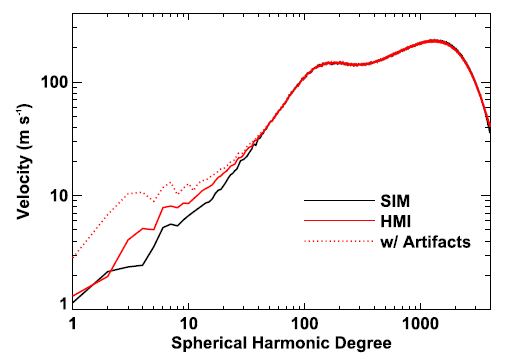

### Peak estimate

If we take the peak have RMS of about 1 km/s and lie in the range 0.7-7 Mm it corresponds to spherical harmonic degrees of around 100 to 1000, and therefore a power density per unit wavenumber

In [ ]:
Powerdensity=1e5**2/(900*k1)
Powerdensity

In [ ]:
k1=2*pi/(2*pi*c.R_sun.cgs)
Power=900.*k1*Powerdensity
velocity=Power**0.5
velocity.decompose()/1e5

In [ ]:
c.R_sun.cgs

In [ ]:
nw=32**3
nb=nw*4
ns=65
nc=80
nb*nc*ns/1e9

## Hotta's simulations
These are used in for example the papers Hotta et al (2016, Science), and Hotta et al (2019, Science Advances).  In particular, this panel in Fig 4. of the 2019 paper deserves attention:

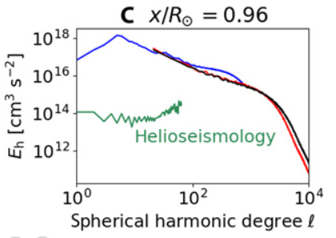

The figure indicates an approximately flat power spectrum over two orders of magnitude in spherical harmonic degree. From the figure we can pick up a power density of about $10^{14}$ cm$^3$s$^{-2}$, and hence we can compute the integrated power, and from that the velocity amplitude:

In [ ]:
Powerdensity=1e14*u.cm**3/u.s**2
k1=2*pi/(2.*pi*c.R_sun.cgs)
Power=100*k1*Powerdensity
velocity=Power**0.5
velocity.decompose()

So, this corresponds to a velocity of motions at spherical harmonic degree $\ell<100$ of less than 4 m/s.   The power per unit log interval of wave number is proportional to wave number, so this corresponds to a rising spectrum in amplitude of motion per unit log wavenumber, which would reach 40 m/s over the next order of magnitude, which includes the peak in power at granulations scales.

This would be too low at surface, but might be resonable at the depth of sensitivity. On the other hand the simulations have a power density of at least $10^{17}$ times over the same interval.  It would correspond to motions with a total power of about 30 times larger for harmonic degrees $\ell < 100$, or about 100 m/s, which may by a bit too high.